# Performance — success rate, RT, ET and MD

Generates learning-curve plots saved into `figures/s<sn>/performance/`:

| file | measure |
|---|---|
| `01_success_rate.png` | % of trials correct |
| `02_reaction_time.png` | RT of correct trials |
| `03_execution_time.png` | ET of correct trials |
| `04_mean_deviation.png` | MD of correct trials |

Each figure also comes in a `_pooled` version (e.g. `01_success_rate_pooled.png`) where
Test 1 and Test 2 are each collapsed to one data point per chord,
for reading off the overall pre-to-post change.
For ongoing data collections, blocks without data are hatched: not yet collected, e.g., for s100, which stopped after
Test 2.

The 4-finger chords get roughly 5 trials each per block (fewer in some blocks, since
the trial order is shuffled in pairs), so their per-block points are noisy; the error
bars are drawn faintly for that reason.

RT, ET and MD are plotted as medians.

Reads `analysis/s<sn>.csv` from `preprocess.ipynb`.

## Imports

In [ ]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D

# project root = the folder that contains target/ and data/
ROOT = Path.cwd()
while not (ROOT / "target").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from utils import timeline
from utils.chords import ChordRoles
from utils.design import SEGMENTS
from utils.stats import median_ci

SN = 101
SEED = 1517            # <<< for the bootstrap error bars

ANALYSIS_DIR = ROOT / "analysis"
FIG_DIR = ROOT / "figures" / f"s{SN}" / "performance"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="ticks", context="notebook",
              rc={"axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv(ANALYSIS_DIR / f"s{SN}.csv")
COLLECTED = set(df.BN.unique())
rng = np.random.default_rng(SEED)
print(f"s{SN}: {len(df)} trials, blocks {df.BN.min()}-{df.BN.max()}")


s101: 1040 trials, blocks 1-52


## Chord roles

Which component each tested chord shares is derived from the data, not hard-coded
(`utils/chords.py`), so this works for any counterbalancing group: the trained chords are
whatever appears in the training blocks, and each 4-finger chord is scored by how many of
those components are embedded in it.

In [ ]:
train_blocks = [b for s in SEGMENTS if s["kind"] == "2f" for b in s["blocks"]]
test_blocks = [b for s in SEGMENTS if s["kind"] == "4f" for b in s["blocks"]]

roles = ChordRoles(trained=df.loc[df.BN.isin(train_blocks), "chordID"].unique(),
                   tested=df.loc[df.BN.isin(test_blocks), "chordID"].unique())
TESTED, TRAINED = roles.tested, roles.trained        # tested: both -> 1st -> 2nd -> neither
LABEL, COLOR, MARKER = roles.label, roles.color, roles.marker
for c in TESTED + TRAINED:
    print(f"  {LABEL[c]}")


  12912  both components trained
  12921  1st component trained
  21912  2nd component trained
  21921  neither component trained
  12999  trained component (1st)
  99912  trained component (2nd)


## Generate the figures

One pass per measure, once per block and once with the tests pooled. `MD` is `NaN` on
incorrect trials by construction, so the correct-trials-only filter is already implicit for
it. Each point summarises the trials of that chord in that block (or test): the median with
a bootstrap 68% interval for RT, ET and MD, the proportion with a binomial SE for success.

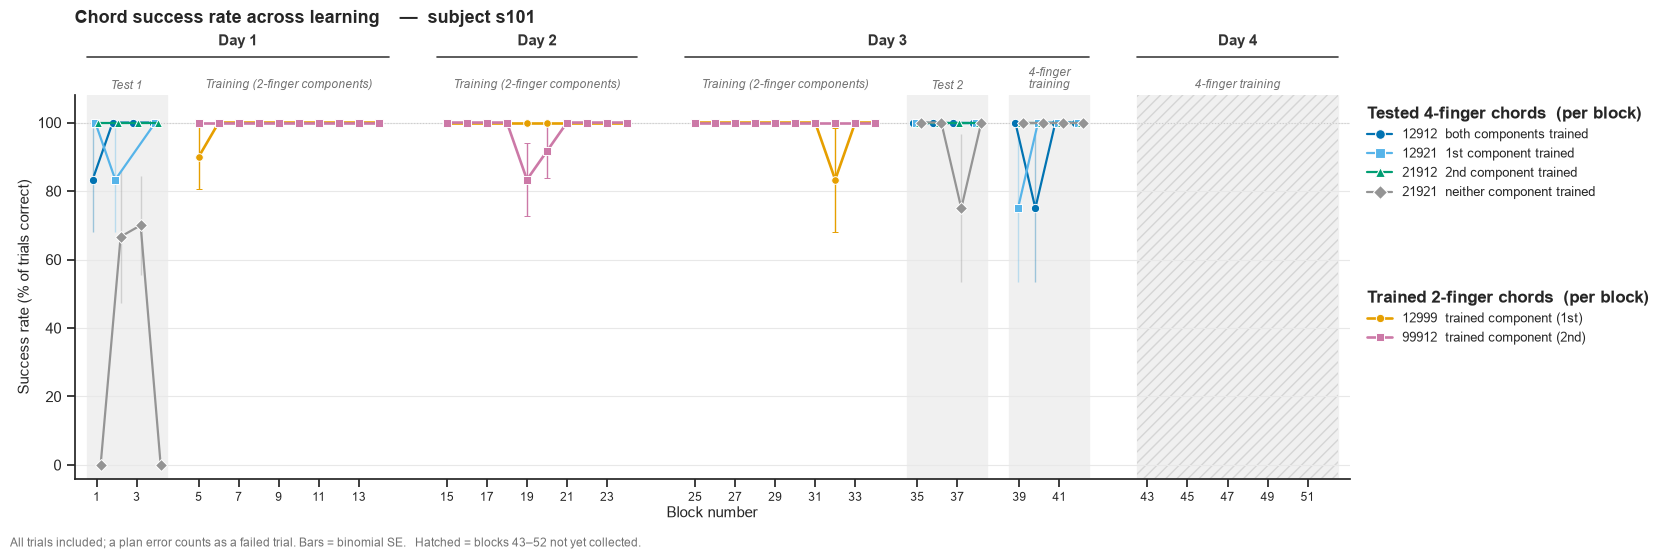

wrote figures/s101/performance/01_success_rate.png


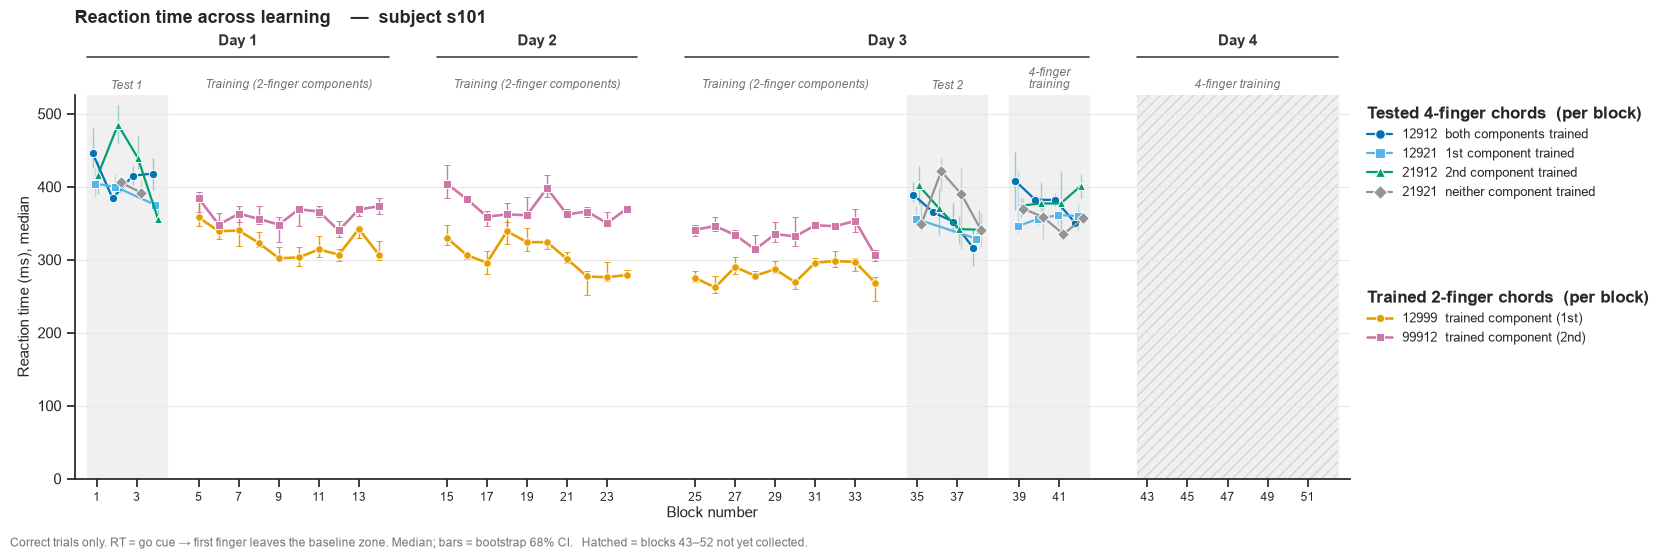

wrote figures/s101/performance/02_reaction_time.png


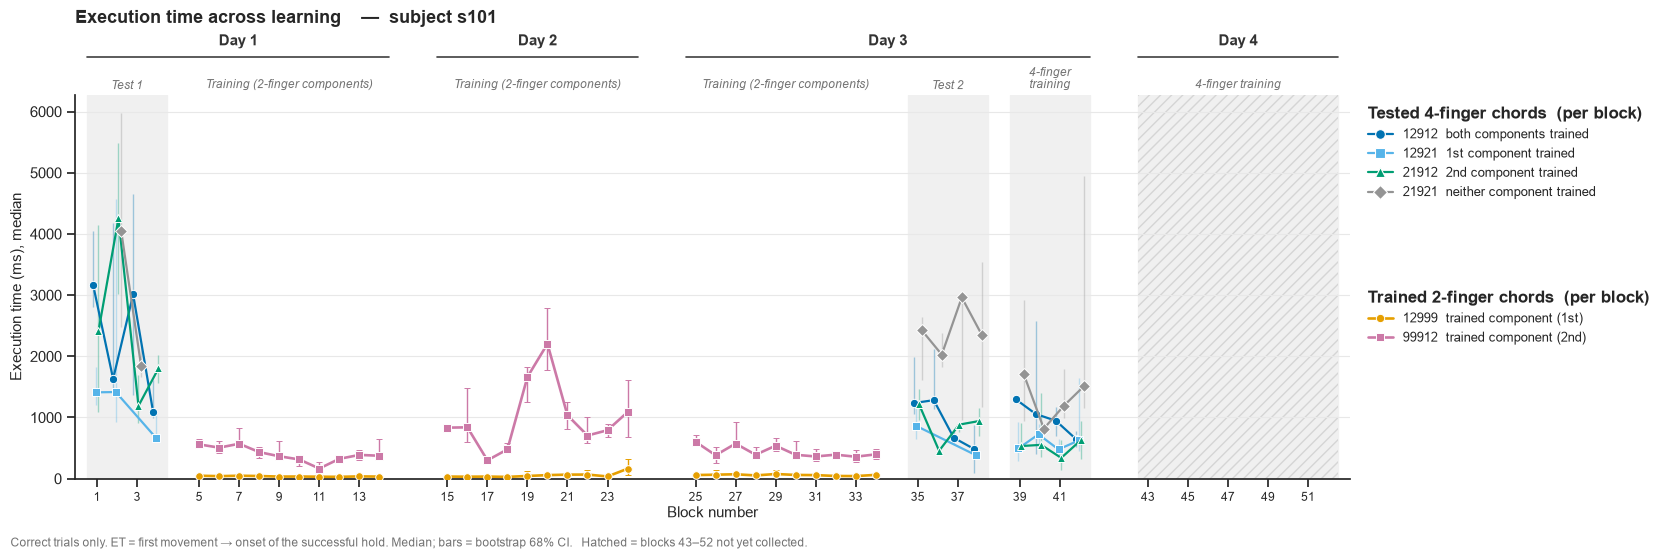

wrote figures/s101/performance/03_execution_time.png


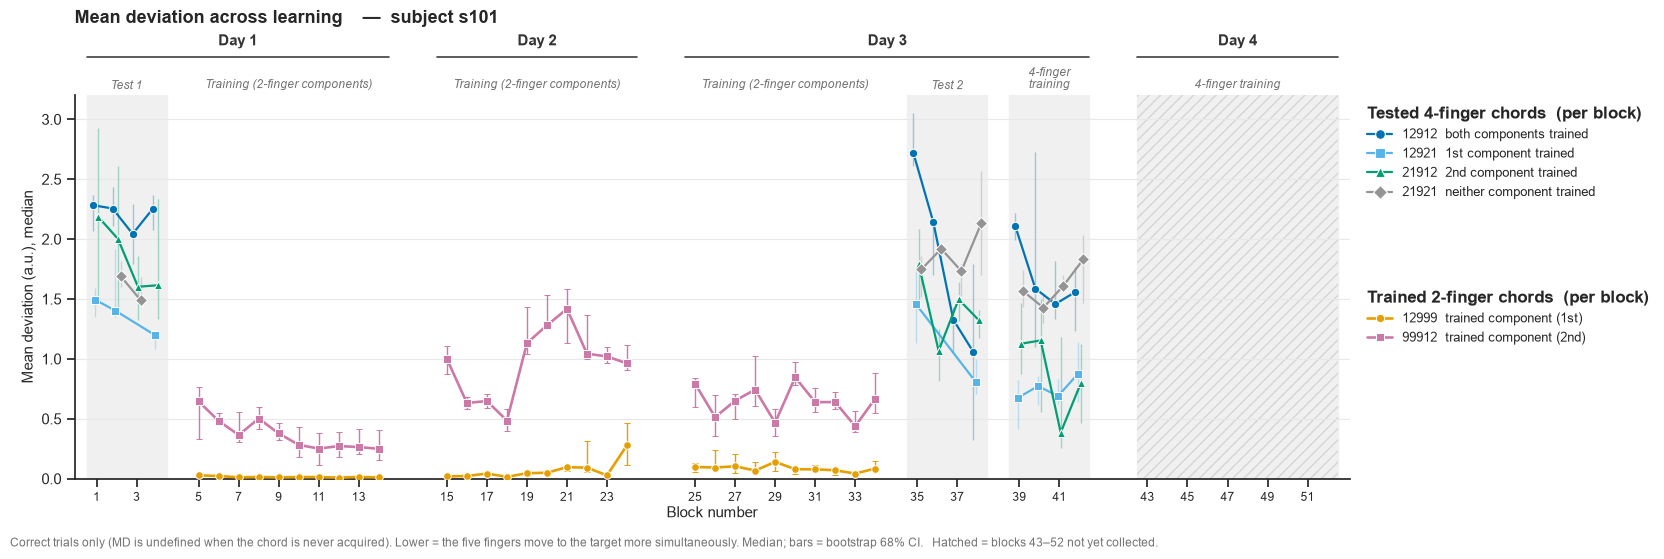

wrote figures/s101/performance/04_mean_deviation.png


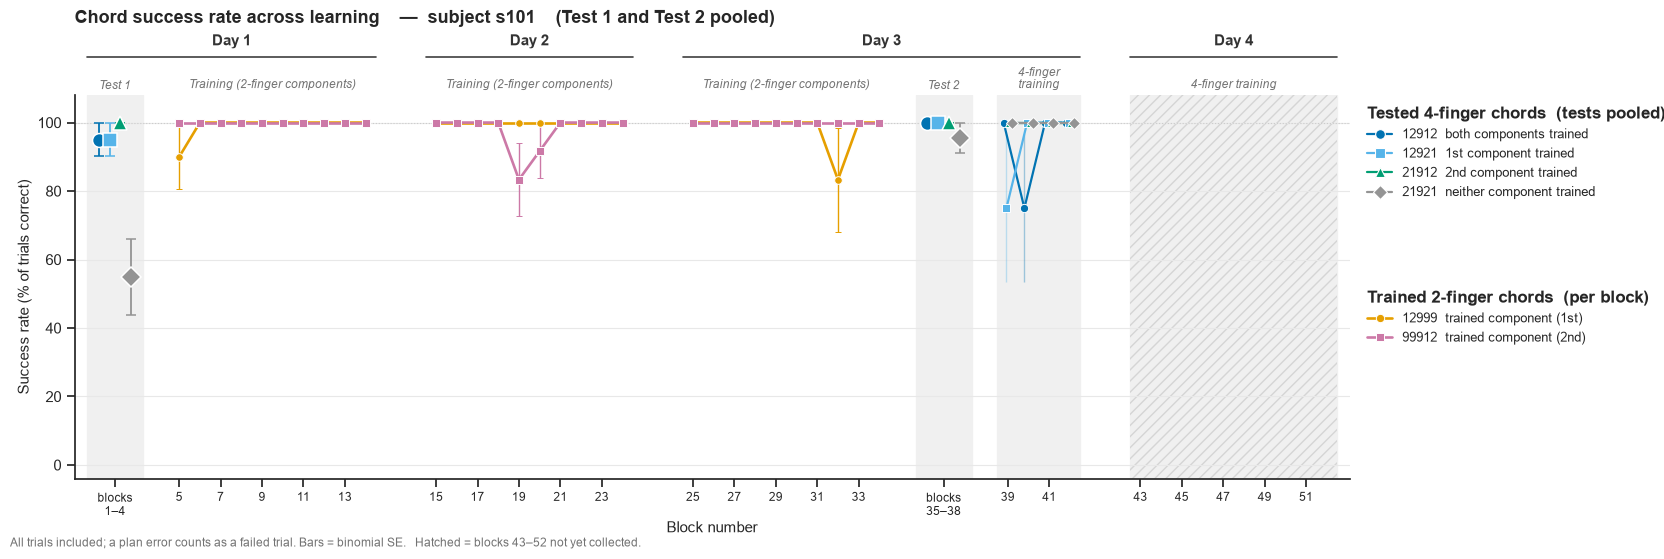

wrote figures/s101/performance/01_success_rate_pooled.png


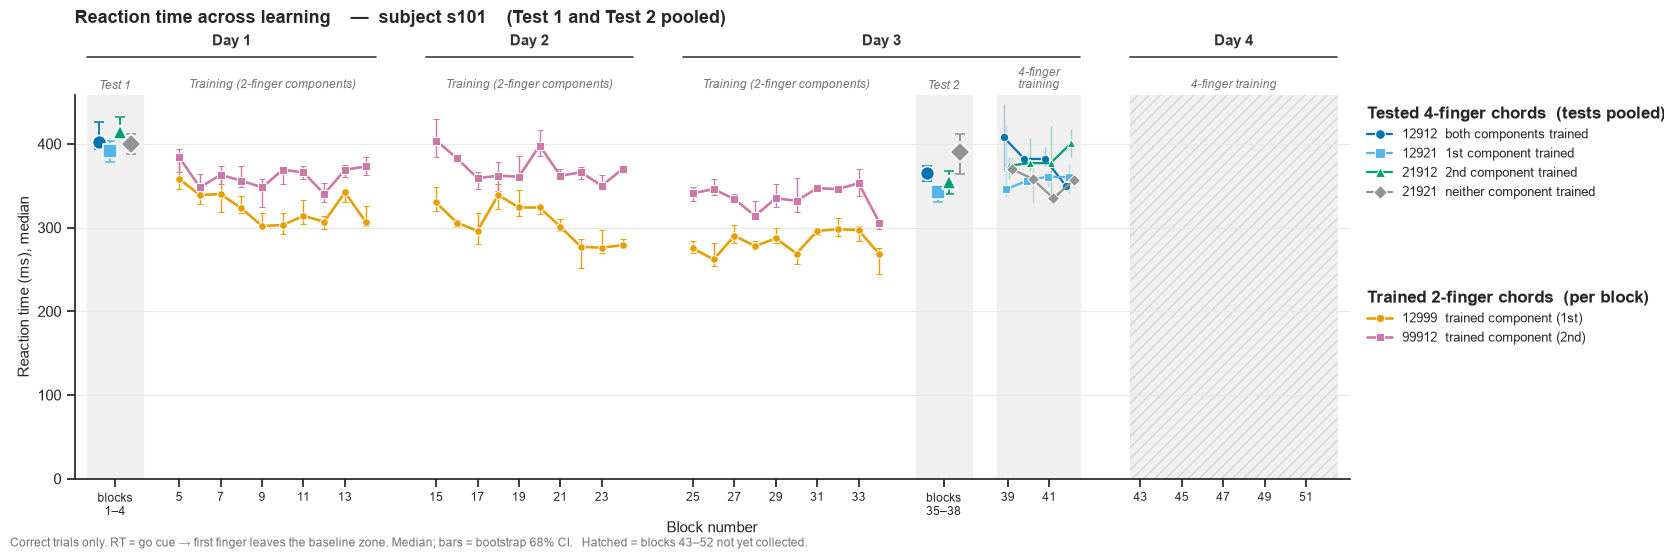

wrote figures/s101/performance/02_reaction_time_pooled.png


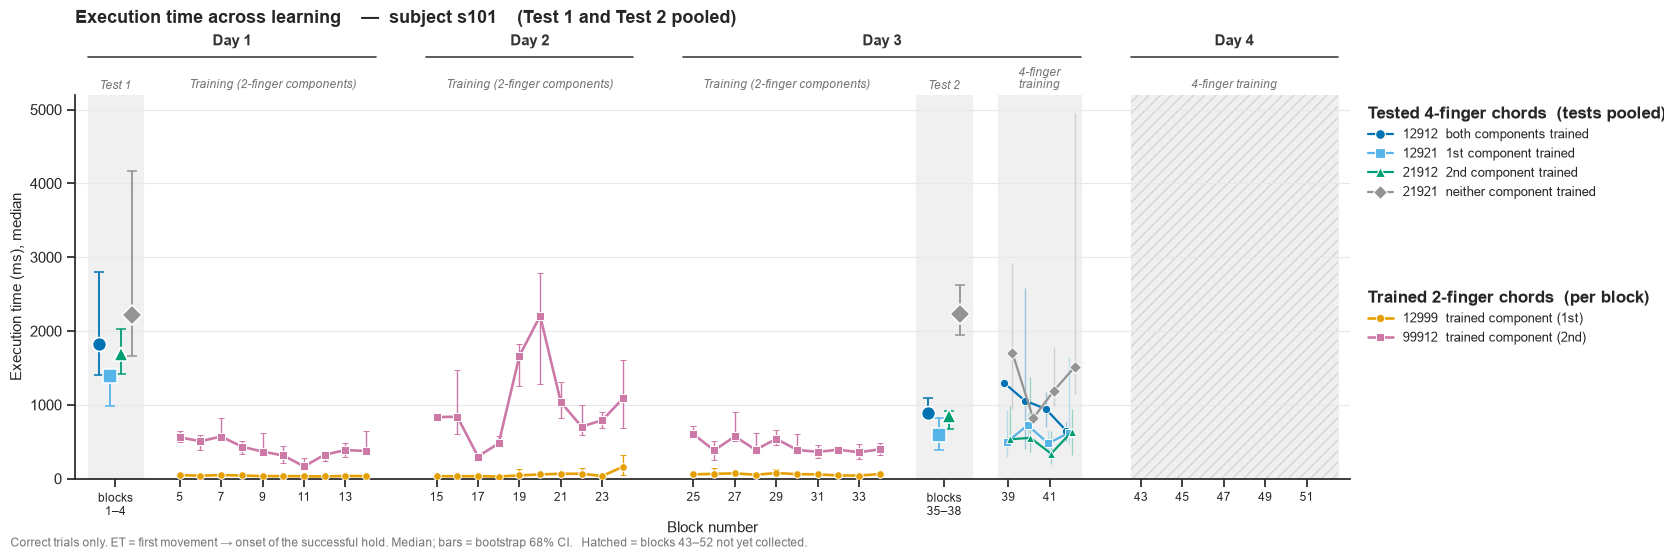

wrote figures/s101/performance/03_execution_time_pooled.png


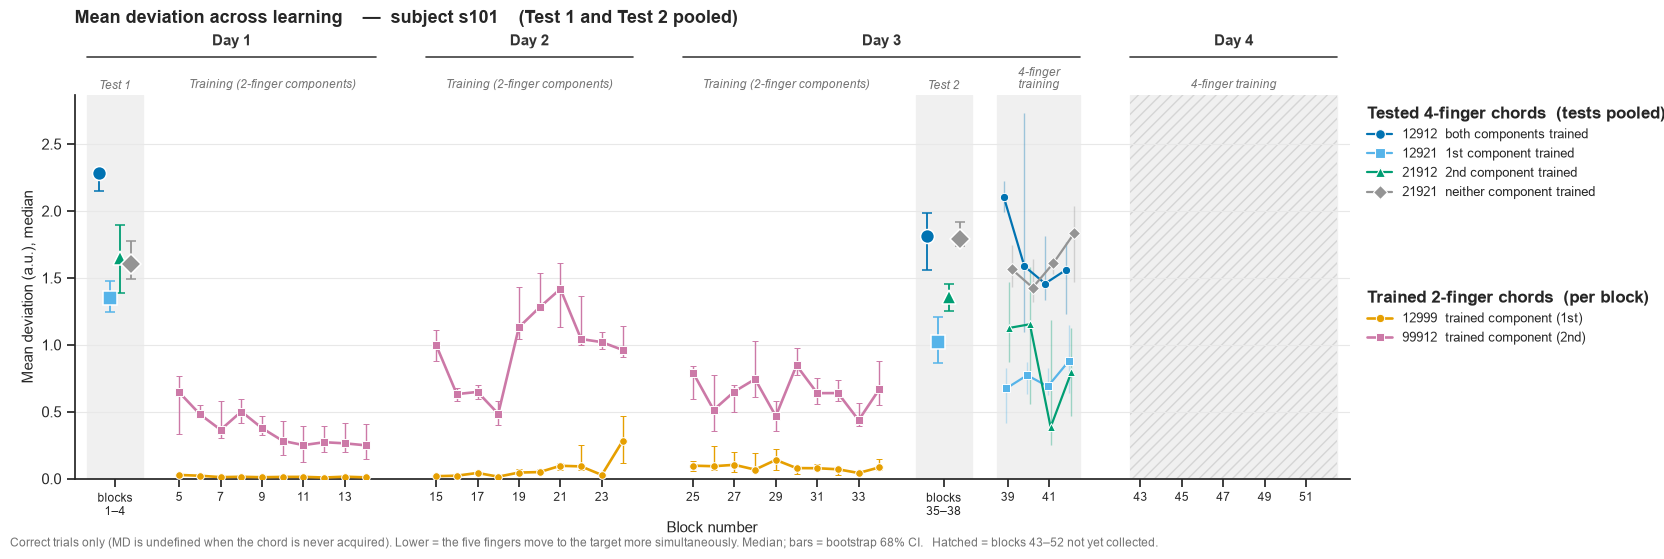

wrote figures/s101/performance/04_mean_deviation_pooled.png


In [3]:
MEASURES = [
    dict(col="trialPoint", fname="01_success_rate.png",
         ylabel="Success rate (% of trials correct)",
         title="Chord success rate across learning",
         note="All trials included; a plan error counts as a failed trial. Bars = binomial SE.",
         correct_only=False, scale=100),
    dict(col="RT", fname="02_reaction_time.png",
         ylabel="Reaction time (ms), median",
         title="Reaction time across learning",
         note=("Correct trials only. RT = go cue → first finger leaves the baseline zone. "
               "Median; bars = bootstrap 68% CI."),
         correct_only=True, scale=1),
    dict(col="ET", fname="03_execution_time.png",
         ylabel="Execution time (ms), median",
         title="Execution time across learning",
         note=("Correct trials only. ET = first movement → onset of the successful hold. "
               "Median; bars = bootstrap 68% CI."),
         correct_only=True, scale=1),
    dict(col="MD", fname="04_mean_deviation.png",
         ylabel="Mean deviation (a.u.), median",
         title="Mean deviation across learning",
         note=("Correct trials only (MD is undefined when the chord is never acquired). "
               "Lower = the five fingers move to the target more simultaneously. "
               "Median; bars = bootstrap 68% CI."),
         correct_only=True, scale=1),
]

# the four 4-finger chords share every slot, so nudge them apart around its x
dodge = dict(zip(TESTED, np.linspace(-0.2, 0.2, len(TESTED))))
dodge_pooled = dict(zip(TESTED, np.linspace(-0.78, 0.78, len(TESTED))))

def summarise(v, meas):
    """Point and (below, above) error bar for one chord in one block.

    Success rate: proportion +/- binomial SE. RT / ET / MD: median with a bootstrap 68% CI.
    """
    if meas["col"] == "trialPoint":
        m = v.mean()
        e = np.sqrt(m * (1 - m) / len(v))
        return meas["scale"] * m, (meas["scale"] * e, meas["scale"] * e)
    m, (lo, hi) = median_ci(v, rng)
    return meas["scale"] * m, (meas["scale"] * lo, meas["scale"] * hi)


for pool_tests, meas in [(p, m) for p in (False, True) for m in MEASURES]:
    segs = timeline.layout(pool_tests)
    fname = meas["fname"].replace(".png", "_pooled.png") if pool_tests else meas["fname"]
    fig, ax = plt.subplots(figsize=(17, 5.9))

    timeline.draw_background(ax, segs, COLLECTED)

    # pooled tests: one point per chord over all of the segment's blocks
    for seg in segs:
        if not seg["pooled"]:
            continue
        for c in TESTED:
            d = df[(df.BN.isin(seg["blocks"])) & (df.chordID == c)]
            if meas["correct_only"]:
                d = d[d.trialPoint == 1]
            v = d[meas["col"]].dropna()
            if len(v) == 0:
                continue
            m, e = summarise(v, meas)
            ax.errorbar(seg["center"] + dodge_pooled[c], m, yerr=np.reshape(e, (2, 1)), color=COLOR[c],
                        marker=MARKER[c], ms=10, lw=0, capsize=3.5, elinewidth=1.3,
                        mec="white", mew=1.1, zorder=4)

    # everything else: one point per block per chord; lines join the blocks of a segment
    for seg in segs:
        if seg["pooled"]:
            continue
        four = seg["kind"] == "4f"
        for c in (TESTED if four else TRAINED):
            xs, ys, es = [], [], []
            for b in seg["blocks"]:
                d = df[(df.BN == b) & (df.chordID == c)]
                if meas["correct_only"]:
                    d = d[d.trialPoint == 1]
                v = d[meas["col"]].dropna()
                if len(v) == 0:
                    continue
                m, e = summarise(v, meas)
                xs.append(seg["x"][b] + (dodge[c] if four else 0))
                ys.append(m)
                es.append(e)
            if not xs:
                continue
            eb = ax.errorbar(xs, ys, yerr=np.array(es).T, color=COLOR[c], marker=MARKER[c],
                             ms=6 if four else 5.5, lw=1.6 if four else 1.9,
                             capsize=0 if four else 2.5, elinewidth=1,
                             mec="white", mew=.7, zorder=4 if four else 3)
            if four:                       # ~5 trials per point: keep the bars quiet
                for coll in eb[2]:
                    coll.set_alpha(.35)

    if meas["col"] == "trialPoint":
        ax.set_ylim(-4, 108)
        ax.axhline(100, color="0.8", lw=.8, ls=":", zorder=1)
    else:
        ax.set_ylim(bottom=0)

    ax.set_ylabel(meas["ylabel"], fontsize=11)
    ax.set_xlabel("Block number", fontsize=11, labelpad=2)
    ax.grid(axis="y", color="0.91", lw=.8); ax.set_axisbelow(True)

    timeline.draw_axis(ax, segs)

    h_test = [Line2D([], [], color=COLOR[c], marker=MARKER[c], ms=7, lw=1.6,
                     mec="white", mew=.8, label=LABEL[c]) for c in TESTED]
    h_train = [Line2D([], [], color=COLOR[c], marker=MARKER[c], ms=6, lw=1.9,
                      mec="white", mew=.7, label=LABEL[c]) for c in TRAINED]
    leg1 = ax.legend(handles=h_test, title=("Tested 4-finger chords  (tests pooled)" if pool_tests
                            else "Tested 4-finger chords  (per block)"),
                     loc="upper left", bbox_to_anchor=(1.005, 1.0), frameon=False,
                     fontsize=9, labelspacing=.5)
    leg1._legend_box.align = "left"; leg1.get_title().set_fontweight("bold")
    ax.add_artist(leg1)
    leg2 = ax.legend(handles=h_train, title="Trained 2-finger chords  (per block)",
                     loc="upper left", bbox_to_anchor=(1.005, .52), frameon=False,
                     fontsize=9, labelspacing=.5)
    leg2._legend_box.align = "left"; leg2.get_title().set_fontweight("bold")

    foot = meas["note"] + timeline.missing_note(SN, COLLECTED)
    fig.text(.012, .015, foot, fontsize=8.5, color="0.45", ha="left")
    ax.set_title(f"{meas['title']}    —  subject s{SN}"
                 + ("    (Test 1 and Test 2 pooled)" if pool_tests else ""), fontsize=13,
                 fontweight="bold", pad=52, loc="left", color="0.15")
    sns.despine(ax=ax)
    fig.subplots_adjust(left=.05, right=.80, top=.78, bottom=.13)
    fig.savefig(FIG_DIR / fname, dpi=200, facecolor="white")
    plt.show()
    print(f"wrote {(FIG_DIR / fname).relative_to(ROOT)}")